# Análise exploratória — Porto Alegre, Censo 2022, CNEFE, S2iD e INCT

**Projeto de CPA — enchentes e exposição territorial**  
**Base de dados:** arquivos processados disponibilizados no projeto `PROJETO_INCT_Luiza`.

### Objetivo
Explorar população e domicílios dos bairros de Porto Alegre, características dos endereços do CNEFE, registros de desastres do S2iD e **cenários de inundação** do JSON do INCT.

**Cuidados de interpretação:** o Censo é de 2022, os dados do CNEFE referem-se a uma base distinta e o JSON apresenta cenários por cota (metros), **não uma série temporal**. Nenhuma dessas bases mede diretamente rendimento escolar ou desempenho no ENEM. As análises são descritivas e não permitem atribuir causalidade às enchentes de 2024.

## 1. Configuração e carregamento
Execute as células na ordem. O notebook procura a pasta `dados/processados` tanto ao ser aberto na raiz quanto em `notebooks/`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True})

candidatas = [Path.cwd(), Path.cwd().parent]
raiz = next((p for p in candidatas if (p / 'dados' / 'processados' / 'censo_bairros_poa.csv').exists()), None)
if raiz is None:
    raise FileNotFoundError('Não encontrei dados/processados/. Abra o notebook na raiz do repositório ou em notebooks/.')
print('Raiz do projeto:', raiz)
base = raiz / 'dados' / 'processados'
bairros = pd.read_csv(base / 'censo_bairros_poa.csv')
cnefe = pd.read_csv(base / 'cnefe_resumo_bairro.csv')
validacao = pd.read_csv(base / 'validacao_censo_inct.csv')
s2id = pd.read_csv(base / 's2id_poa.csv')
with (raiz / 'dados' / 'referencia' / 'data.json').open(encoding='utf-8') as arquivo:
    inct = json.load(arquivo)
print('Arquivos carregados.')

Raiz do projeto: /mnt/data/inct_work/PROJETO_INCT_Luiza
Arquivos carregados.


## 2. Dimensões das bases e qualidade básica

In [2]:
tamanhos = pd.DataFrame([
    {'base': 'Censo 2022 — bairros', 'linhas': len(bairros), 'colunas': bairros.shape[1]},
    {'base': 'CNEFE — resumo por bairro', 'linhas': len(cnefe), 'colunas': cnefe.shape[1]},
    {'base': 'Validação Censo × INCT', 'linhas': len(validacao), 'colunas': validacao.shape[1]},
    {'base': 'S2iD — Porto Alegre', 'linhas': len(s2id), 'colunas': s2id.shape[1]},
    {'base': 'INCT — cenários de nível da água', 'linhas': len(inct), 'colunas': np.nan},
])
display(tamanhos)
print('Duplicações de código de bairro no Censo:', bairros['cd_bairro'].duplicated().sum())
print('Divergências Censo × população INCT:', (validacao['dif_pessoas'].fillna(0) != 0).sum())
print('Ausências em colunas selecionadas do Censo:')
display(bairros[['nome_inct','pessoas','dom_particulares','area_km2']].isna().sum().to_frame('ausentes'))

,base,linhas,colunas
0,Censo 2022 — bairros,94,32.0
1,CNEFE — resumo por bairro,94,15.0
2,Validação Censo × INCT,94,8.0
3,S2iD — Porto Alegre,24,27.0
4,INCT — cenários de nível da água,71,NaN


Duplicações de código de bairro no Censo: 0
Divergências Censo × população INCT: 0
Ausências em colunas selecionadas do Censo:


,ausentes
nome_inct,0
pessoas,0
dom_particulares,0
area_km2,0


## 3. População nos bairros (Censo 2022)
A comparação apresenta os dez bairros mais populosos, sem implicar que foram os mais afetados pela enchente.

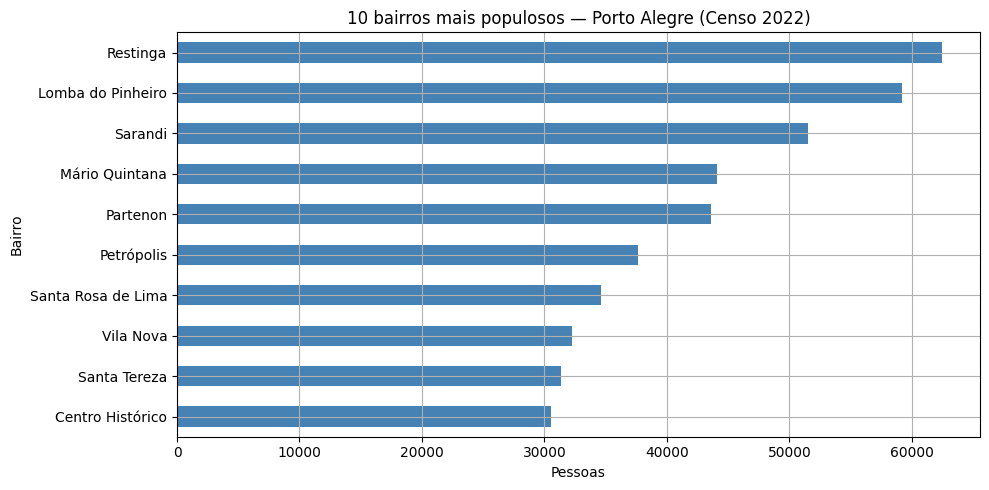

População total nos 94 bairros: 1.332.845


In [3]:
top_pop = bairros.nlargest(10, 'pessoas')[['nome_inct', 'pessoas']].sort_values('pessoas')
ax = top_pop.plot.barh(x='nome_inct', y='pessoas', legend=False, color='steelblue')
ax.set(title='10 bairros mais populosos — Porto Alegre (Censo 2022)', xlabel='Pessoas', ylabel='Bairro')
plt.tight_layout(); plt.show()
print('População total nos 94 bairros:', f"{bairros['pessoas'].sum():,.0f}".replace(',', '.'))

## 4. Domicílios e endereços (Censo × CNEFE)
As duas bases utilizam recortes e métodos distintos para atribuição territorial. **Diferenças por bairro não são necessariamente erros.** A quantidade de endereços também não equivale ao número de edificações.

,nome_inct,dom_particulares,dom_particulares_cnefe,dif_dom_part_cnefe_censo
56,Mário Quintana,18144,18645,501
70,Rubem Berta,14159,13687,-472
28,Farroupilha,517,786,269
38,Jardim Carvalho,11116,11370,254
37,Jardim Botânico,6901,7146,245
55,Morro Santana,10792,10551,-241
75,Santana,12104,11864,-240
67,Praia de Belas,1240,1470,230
29,Floresta,5853,5634,-219
53,Moinhos de Vento,6896,7090,194


Domicílios particulares Censo: 686846
Domicílios particulares CNEFE: 686821


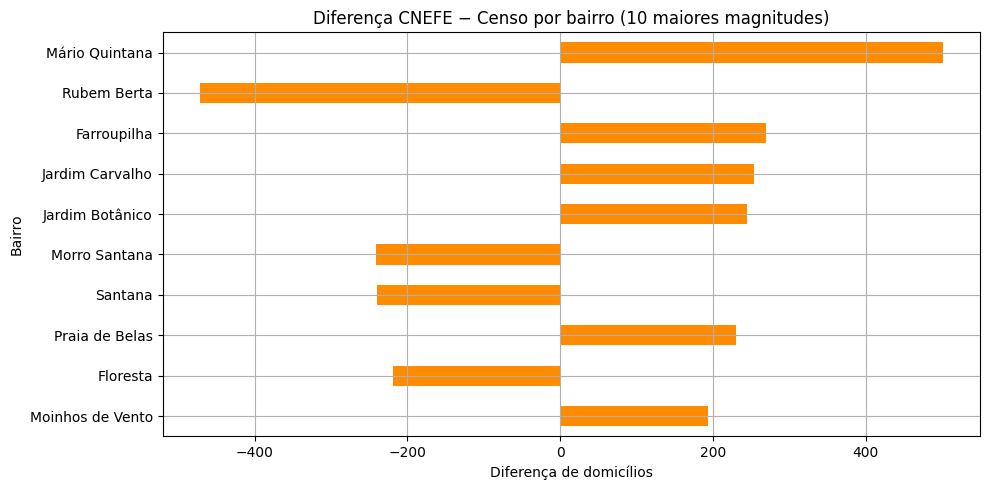

In [4]:
comparacao = cnefe[['nome_inct','dom_particulares','dom_particulares_cnefe','dif_dom_part_cnefe_censo']].copy()
comparacao['diferenca_absoluta'] = comparacao['dif_dom_part_cnefe_censo'].abs()
display(comparacao.nlargest(10, 'diferenca_absoluta').drop(columns='diferenca_absoluta'))
print('Domicílios particulares Censo:', int(comparacao['dom_particulares'].sum()))
print('Domicílios particulares CNEFE:', int(comparacao['dom_particulares_cnefe'].sum()))
ax = comparacao.nlargest(10, 'diferenca_absoluta').sort_values('diferenca_absoluta').plot.barh(
    x='nome_inct', y='dif_dom_part_cnefe_censo', color='darkorange', legend=False)
ax.set(title='Diferença CNEFE − Censo por bairro (10 maiores magnitudes)', xlabel='Diferença de domicílios', ylabel='Bairro')
plt.tight_layout(); plt.show()

## 5. Eventos de desastres registrados em Porto Alegre — S2iD
Contamos registros principais para evitar dupla contagem dos eventos repetidos sinalizados pela limpeza. **O tipo de desastre em 2024 pode estar classificado como chuvas intensas**, não apenas inundação.

,ano,registros_principais
0,2014,1
1,2015,1
2,2016,1
3,2017,3
4,2018,1
5,2019,1
6,2020,4
7,2021,3
8,2022,1
9,2023,4


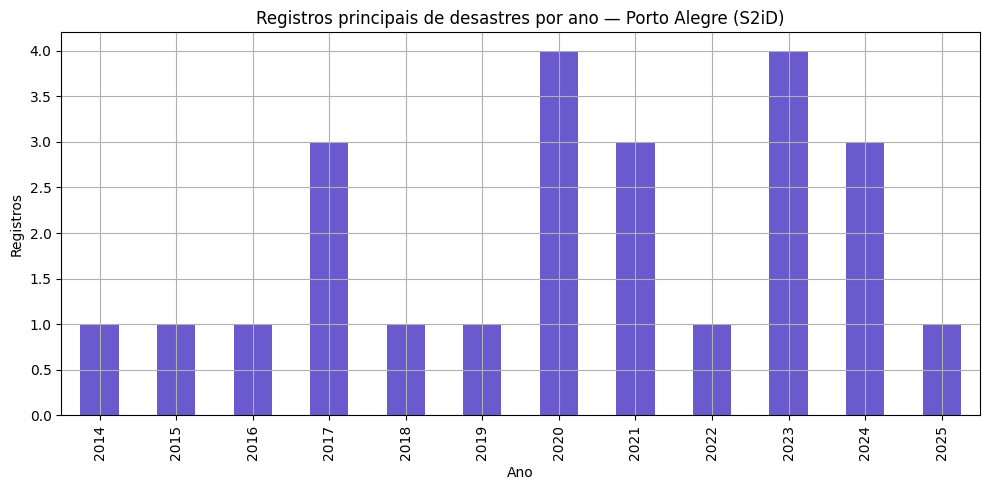

Registros da base S2iD com data em 2024:


,dt,cobrade,cobrade_tipo,grp,status,proto
0,2024-01-16,13214,chuvas_intensas,storm,Reconhecido,RS-F-4314902-13214-20240116
1,2024-04-29,13214,chuvas_intensas,storm,Reconhecido,RS-F-4314902-13214-20240429
2,2024-12-24,13214,chuvas_intensas,storm,Não reconhecido,RS-F-4314902-13214-20241224


In [5]:
s2id['dt'] = pd.to_datetime(s2id['dt'], errors='coerce')
principais = s2id.loc[s2id['registro_principal'].fillna(False).astype(bool)].copy()
por_ano = principais.groupby(principais['dt'].dt.year).size().rename('registros_principais').reset_index()
por_ano.columns = ['ano', 'registros_principais']
display(por_ano)
ax = por_ano.plot.bar(x='ano', y='registros_principais', legend=False, color='slateblue')
ax.set(title='Registros principais de desastres por ano — Porto Alegre (S2iD)', ylabel='Registros', xlabel='Ano')
plt.tight_layout(); plt.show()
print('Registros da base S2iD com data em 2024:')
display(principais.loc[principais['dt'].dt.year == 2024,
    ['dt','cobrade','cobrade_tipo','grp','status','proto']].sort_values('dt').reset_index(drop=True))

## 6. Cenário de inundação no INCT
O `data.json` oferece **níveis de água (por exemplo, `4_0m`)**. A cota selecionada abaixo é um **cenário ilustrativo para comparação**, e não a medição de uma data ou um retrato automático da enchente de maio de 2024. A população afetada é estimada pelo modelo do INCT.

Cenário: 4_0m | bairros: 94
População estimada exposta (soma dos bairros): 84970


,bairro,population,affected_population,pct_populacao_exposta,affected_buildings
27,Farrapos,17591,17591,100.000000,5507
82,Sarandi,51539,13401,26.001669,5483
34,Humaitá,12744,12744,100.000000,2087
53,Menino Deus,27961,8389,30.002503,1655
3,Arquipélago,6411,6411,100.000000,4685
78,São Geraldo,6948,3613,52.000576,1781
29,Floresta,8798,3168,36.008184,1330
57,Navegantes,3315,2752,83.016591,2651
49,Lami,6677,2538,38.011083,1447
79,São João,10621,1806,17.004049,527


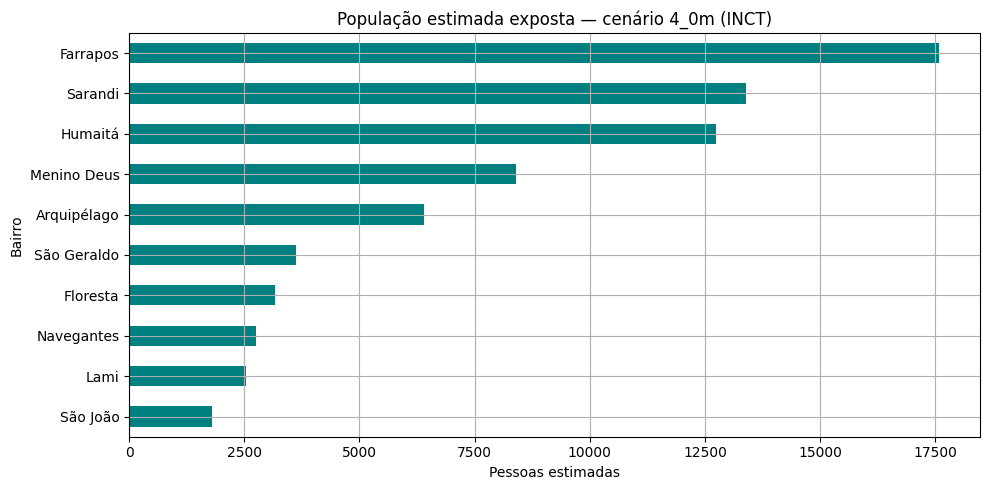

In [6]:
CENARIO = '4_0m'  # altere para outra chave válida, por exemplo: 3_5m ou 5_0m
assert CENARIO in inct, f'Cenário inexistente: {CENARIO}'
exposicao = pd.DataFrame.from_dict(inct[CENARIO], orient='index').rename_axis('bairro').reset_index()
for col in ['affected_buildings','total_buildings','population','affected_population']:
    exposicao[col] = pd.to_numeric(exposicao[col], errors='coerce')
exposicao['pct_populacao_exposta'] = np.where(
    exposicao['population'] > 0,
    100 * exposicao['affected_population'] / exposicao['population'], np.nan)
print('Cenário:', CENARIO, '| bairros:', len(exposicao))
print('População estimada exposta (soma dos bairros):', int(exposicao['affected_population'].sum()))
display(exposicao.nlargest(10, 'affected_population')[
    ['bairro','population','affected_population','pct_populacao_exposta','affected_buildings']])
top_exposicao = exposicao.nlargest(10, 'affected_population').sort_values('affected_population')
ax = top_exposicao.plot.barh(x='bairro', y='affected_population', legend=False, color='teal')
ax.set(title=f'População estimada exposta — cenário {CENARIO} (INCT)', xlabel='Pessoas estimadas', ylabel='Bairro')
plt.tight_layout(); plt.show()

## 7. Comparação entre níveis de água
Como o cenário é uma simulação por cotas, uma curva por nível não deve ser apresentada como evolução histórica das enchentes.

,nivel_m,populacao_estimada_exposta,edificacoes_afetadas
0,3.0,34605,15264
1,3.1,40196,17344
2,3.2,43524,18453
3,3.3,50922,20345
4,3.4,54858,21753
5,3.5,58066,22454
6,3.6,61696,24007
7,3.7,65410,26088


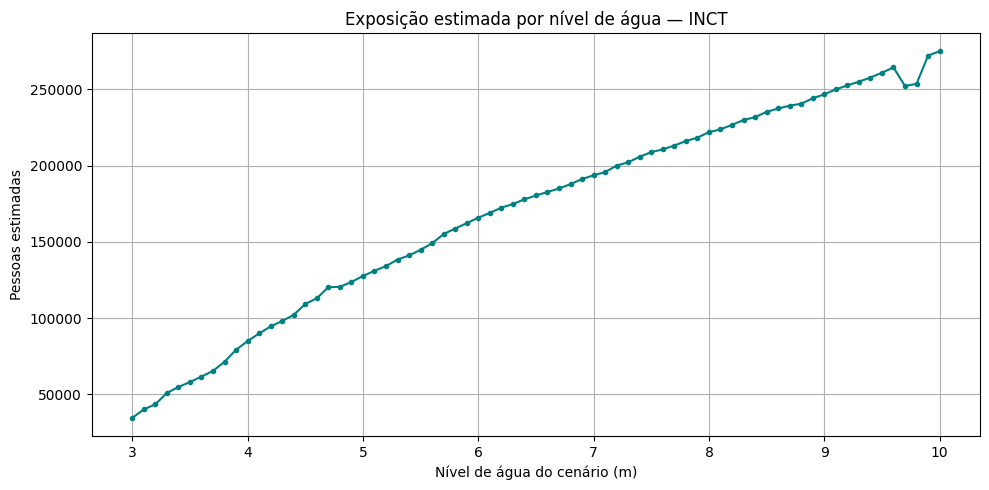

In [7]:
cenario_resumo = []
for chave, dados_bairro in inct.items():
    nivel = float(chave.replace('m','').replace('_','.'))
    quadro = pd.DataFrame.from_dict(dados_bairro, orient='index')
    cenario_resumo.append({'nivel_m': nivel,
                           'populacao_estimada_exposta': pd.to_numeric(quadro['affected_population'], errors='coerce').sum(),
                           'edificacoes_afetadas': pd.to_numeric(quadro['affected_buildings'], errors='coerce').sum()})
curva = pd.DataFrame(cenario_resumo).sort_values('nivel_m')
display(curva.head(8))
ax = curva.plot.line(x='nivel_m', y='populacao_estimada_exposta', legend=False, marker='.', color='teal')
ax.set(title='Exposição estimada por nível de água — INCT', xlabel='Nível de água do cenário (m)', ylabel='Pessoas estimadas')
plt.tight_layout(); plt.show()

## 8. Interpretação, limitações e próximos passos

**O que estes dados permitem:** descrever a distribuição de população e domicílios, verificar correspondência de números populacionais entre bases, observar registros de desastres e comparar exposição estimada em cenários do INCT.

**O que não permitem concluir:** que a inundação provocou queda de desempenho no ENEM, evasão escolar ou prejuízo educacional. Para investigar essas hipóteses seriam necessárias bases específicas de educação e uma estratégia de comparação temporal/territorial.

**Limitações:** dados de anos e métodos distintos; divergências territoriais entre Censo e CNEFE; classificações administrativas do S2iD; cenários simulados do INCT não são observações diárias. A análise inclui apenas os arquivos efetivamente disponíveis no projeto.

**Reprodutibilidade:** dependências `pandas`, `numpy`, `matplotlib`, `ipython`; coloque este notebook em `notebooks/` na mesma estrutura do repositório, sem modificar os arquivos originais.